<a href="https://colab.research.google.com/github/rizalrfli/PCVK_GANJIL-2026/blob/main/Week10_AFRIZAL_RAFLI_K.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pengolahan Citra dan Visi Komputer (PCVK)
## Modul 10: Dasar-dasar Deteksi Obyek

**Nama:** Afrizal Rafli Kusuma Wardana  
**NIM:** 244107020007  
**Kelas:** TI-3C  
**Jurusan:** Teknologi Informasi, Politeknik Negeri Malang

Notebook ini mengerjakan bagian **D. Tugas Praktikum** Modul 10, subbagian D1 dan D2, sesuai urutan soal dan contoh keluaran pada modul. D3 (tugas pengayaan CNN) tidak termasuk bagian ini.


## Persiapan

Notebook dapat dijalankan di Google Colab maupun lokal. Di Colab, mount Google Drive dan arahkan `KANDIDAT` ke folder `Images` yang sudah diunggah ke Drive. Di lokal, notebook mencari folder aset pada direktori kerja saat ini dan folder `WEEK_10/Images`.

In [ ]:
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Lingkungan lokal, Drive tidak perlu di-mount.')

KANDIDAT = [
    '/content/drive/MyDrive/PCVK/Images',
    'Images',
    'WEEK_10/Images',
    '/content/WEEK_10/Images',
    '/content/PCVK_GANJIL-2026/WEEK_10/Images',
]
BASE = next((p for p in KANDIDAT if os.path.isdir(p)), None)
if BASE is None:
    raise FileNotFoundError('Folder Images tidak ditemukan. Atur salah satu path pada KANDIDAT.')

def path(relative):
    return os.path.join(BASE, relative)

print('Folder citra:', os.path.abspath(BASE))


Lingkungan lokal, Drive tidak perlu di-mount.
Folder citra: C:\Users\rizal\Documents\PCVK_GANJIL-2026\WEEK_10\Images


In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 10
print('OpenCV:', cv.__version__)
print('NumPy :', np.__version__)

def read_image(relative, flags=cv.IMREAD_COLOR):
    image = cv.imread(path(relative), flags)
    if image is None:
        raise FileNotFoundError(f'Citra tidak dapat dibaca: {path(relative)}')
    return image

def show_rgb(ax, image, title):
    ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('on')

def show_gray(ax, image, title):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
    ax.axis('on')


OpenCV: 4.11.0
NumPy : 2.5.3


## D1. Praktikum Deteksi Obyek Dasar

### 1. Import library dan akses gambar

Library yang dipakai mengikuti modul: OpenCV, NumPy, dan Matplotlib. Dataset modul berada di `Images/Object Detection` dan `Images/facedet`; model Haar disimpan di `Images/haarcascades`.

### 2. Template matching dengan enam metode OpenCV

Gambar `cats_and_bunnies.jpg` menjadi citra masukan, sedangkan `cat2_templatejpg.jpg` menjadi template. Citra diubah ke grayscale agar tiap kanal warna tidak menggandakan perhitungan, sesuai tampilan matriks matching pada modul. Untuk metode SQDIFF, nilai minimum adalah lokasi terbaik. Untuk CCORR dan CCOEFF, nilai maksimum adalah lokasi terbaik.

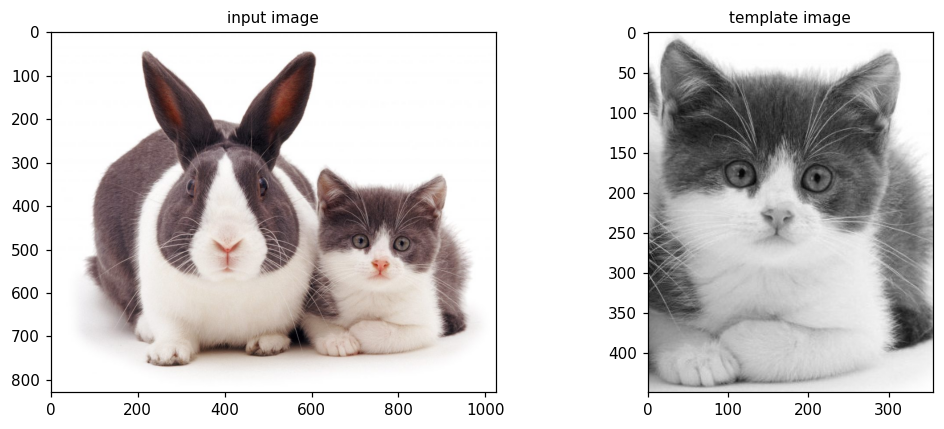

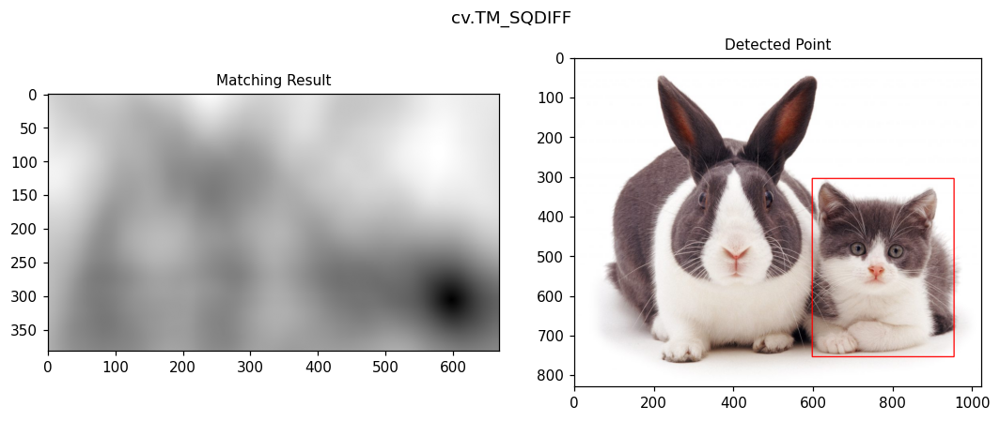

TM_SQDIFF: titik terbaik = (597, 305)


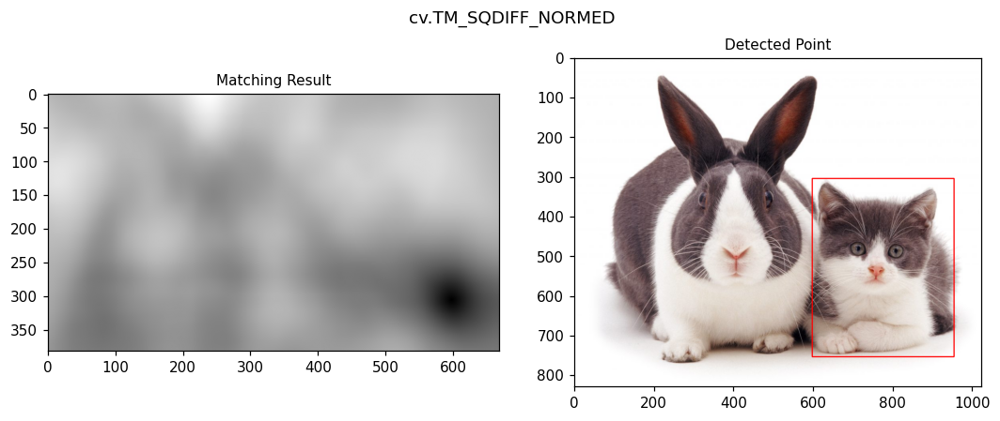

TM_SQDIFF_NORMED: titik terbaik = (597, 305)


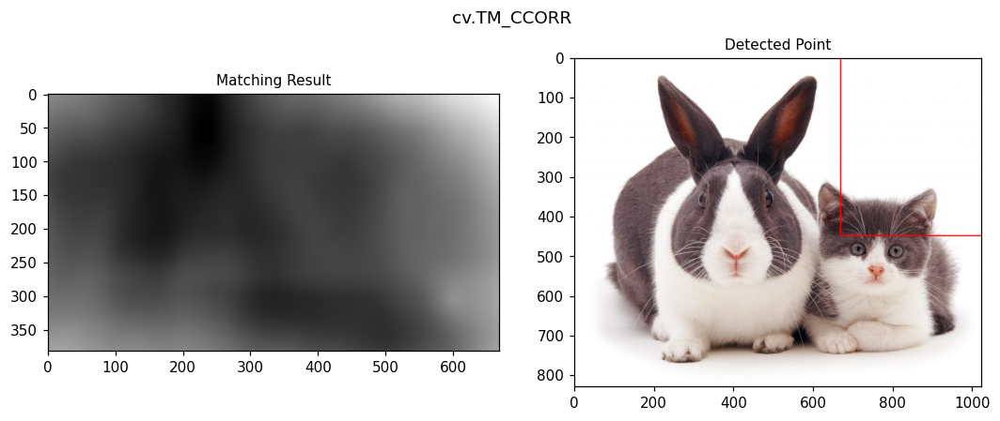

TM_CCORR: titik terbaik = (668, 0)


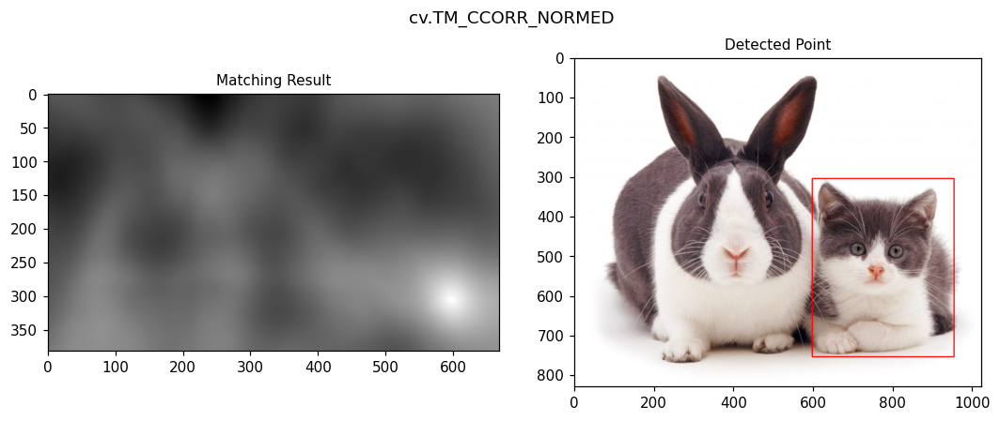

TM_CCORR_NORMED: titik terbaik = (597, 305)


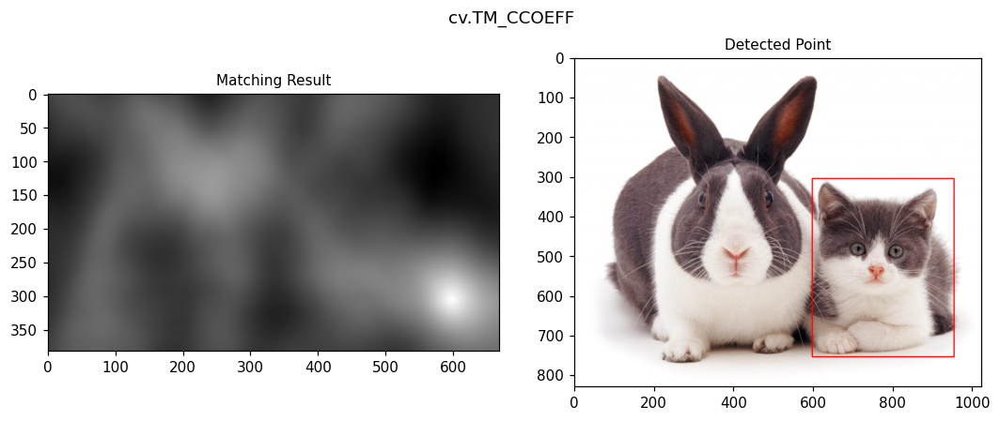

TM_CCOEFF: titik terbaik = (597, 305)


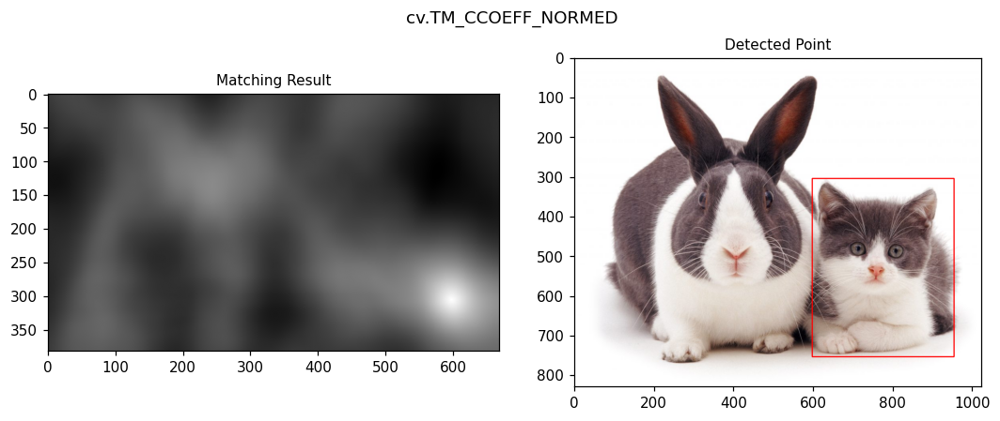

TM_CCOEFF_NORMED: titik terbaik = (597, 305)


In [ ]:
img_color = read_image('Object Detection/cats_and_bunnies.jpg')
template_color = read_image('Object Detection/cat2_templatejpg.jpg')
img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template_color, cv.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
show_rgb(ax[0], img_color, 'input image')
show_gray(ax[1], template_gray, 'template image')
plt.tight_layout()
plt.show()

methods = [
    ('TM_SQDIFF', cv.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv.TM_CCORR),
    ('TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
]
th, tw = template_gray.shape
hasil_matching = {}
for nama, metode in methods:
    result = cv.matchTemplate(img_gray, template_gray, metode)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(result)
    titik = min_loc if metode in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED) else max_loc
    detected = img_color.copy()
    cv.rectangle(detected, titik, (titik[0] + tw, titik[1] + th), (0, 0, 255), 2)
    hasil_matching[nama] = (result, detected, titik)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    show_gray(ax[0], result, 'Matching Result')
    show_rgb(ax[1], detected, 'Detected Point')
    fig.suptitle(f'cv.{nama}')
    plt.tight_layout()
    plt.show()
    print(f'{nama}: titik terbaik = {titik}')


Hasil keenam metode menandai lokasi kucing pada gambar masukan. Hasil antar-metode mempunyai skala dan arah nilai yang berbeda, tetapi pemilihan titik terbaik mengikuti sifat metrik masing-masing.

### 3. Template matching manual untuk banyak obyek

Soal meminta implementasi tanpa fungsi template matching OpenCV. Kode berikut membuat matriks normalized cross-correlation (NCC) dengan NumPy, kemudian memilih puncak tertinggi dan menekan area di sekitar puncak (non-maximum suppression). Penghitungan jendela dibagi per baris agar penggunaan memori lebih terkendali.

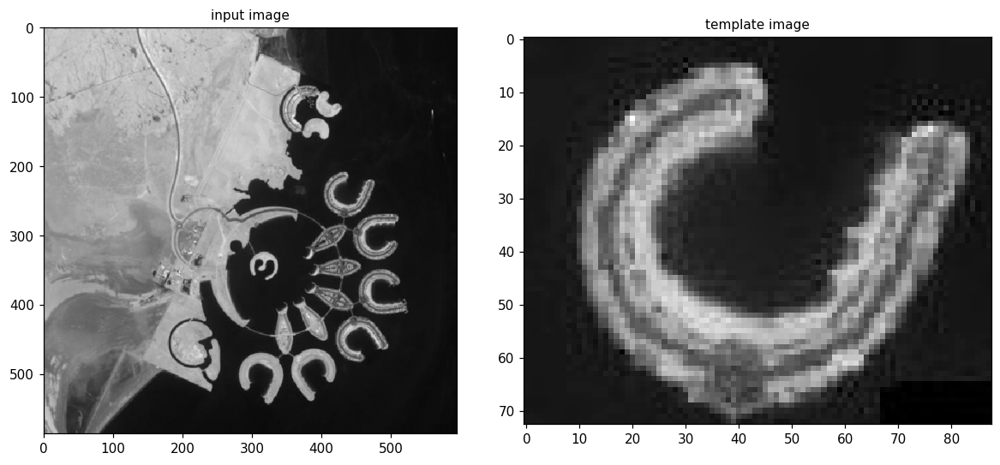

Lokasi: (393, 204), NCC: 0.964
Lokasi: (436, 267), NCC: 0.576
Lokasi: (445, 346), NCC: 0.520
Lokasi: (411, 415), NCC: 0.500
Lokasi: (345, 460), NCC: 0.475
Lokasi: (270, 465), NCC: 0.471


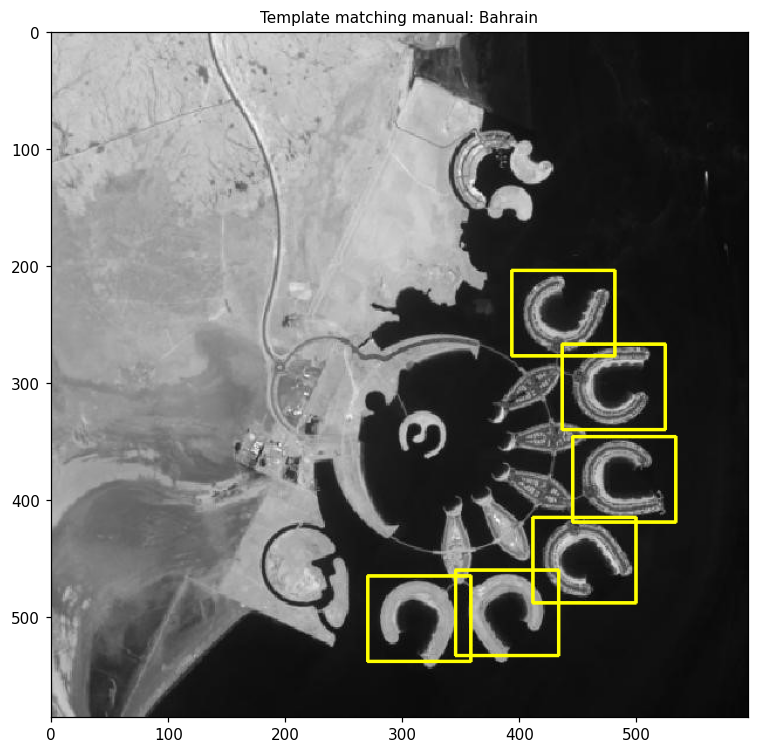

Jumlah obyek terdeteksi: 6


In [ ]:
from numpy.lib.stride_tricks import sliding_window_view

def ncc_manual(image, template, chunk_rows=64):
    image = np.ascontiguousarray(image, dtype=np.float32)
    template = np.asarray(template, dtype=np.float32)
    h, w = template.shape
    centered = template - template.mean()
    template_energy = float((centered * centered).sum())
    n = h * w
    out_h, out_w = image.shape[0] - h + 1, image.shape[1] - w + 1
    result = np.empty((out_h, out_w), dtype=np.float32)

    for y0 in range(0, out_h, chunk_rows):
        y1 = min(y0 + chunk_rows, out_h)
        windows = sliding_window_view(image[y0:y1 + h - 1], (h, w))[:y1 - y0]
        sum_i = windows.sum(axis=(2, 3))
        sum_i2 = (windows * windows).sum(axis=(2, 3))
        numerator = (windows * centered).sum(axis=(2, 3))
        variance = np.maximum(sum_i2 - sum_i * sum_i / n, 1e-6)
        result[y0:y1] = numerator / np.sqrt(template_energy * variance)
    return result

def nms_peaks(response, threshold, box_h, box_w, overlap=0.60):
    work = response.copy()
    detections = []
    pad_y, pad_x = int(box_h * overlap), int(box_w * overlap)
    while True:
        _, score, _, location = cv.minMaxLoc(work)
        if score < threshold:
            break
        x, y = location
        detections.append((x, y, float(score)))
        work[max(0, y - pad_y):y + pad_y + 1,
             max(0, x - pad_x):x + pad_x + 1] = 0
    return detections

bahrain = read_image('Object Detection/bahrain.jpg', cv.IMREAD_GRAYSCALE)
bahrain_template = read_image('Object Detection/bahrain-template.jpg', cv.IMREAD_GRAYSCALE)
response_bahrain = ncc_manual(bahrain, bahrain_template)
bh, bw = bahrain_template.shape
# Ambang 0.45 memisahkan bulan sabit dari gurun, laut, dan jalan.
detections_bahrain = nms_peaks(response_bahrain, 0.45, bh, bw)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
show_gray(ax[0], bahrain, 'input image')
show_gray(ax[1], bahrain_template, 'template image')
plt.tight_layout()
plt.show()

result_bahrain = cv.cvtColor(bahrain, cv.COLOR_GRAY2BGR)
for x, y, score in detections_bahrain:
    cv.rectangle(result_bahrain, (x, y), (x + bw, y + bh), (0, 255, 255), 2)
    print(f'Lokasi: ({x}, {y}), NCC: {score:.3f}')
plt.figure(figsize=(7, 7))
show_rgb(plt.gca(), result_bahrain, 'Template matching manual: Bahrain')
plt.tight_layout()
plt.show()
print('Jumlah obyek terdeteksi:', len(detections_bahrain))


NCC mengukur kemiripan setelah mengurangi rata-rata intensitas lokal. Nilai puncak terkuat berada pada template asal; ambang dan suppression membantu memilih kemunculan lain tanpa menggambar kotak berulang pada lokasi yang sama.

### 4. Sobel, Canny, dan Laplacian Edge Detection

Ketiga metode diterapkan pada `car-park.jpg`. Sobel menghitung gradien X dan Y terpisah, Canny menggunakan dua ambang, sedangkan Laplacian dijalankan setelah Gaussian blur untuk mengurangi noise.

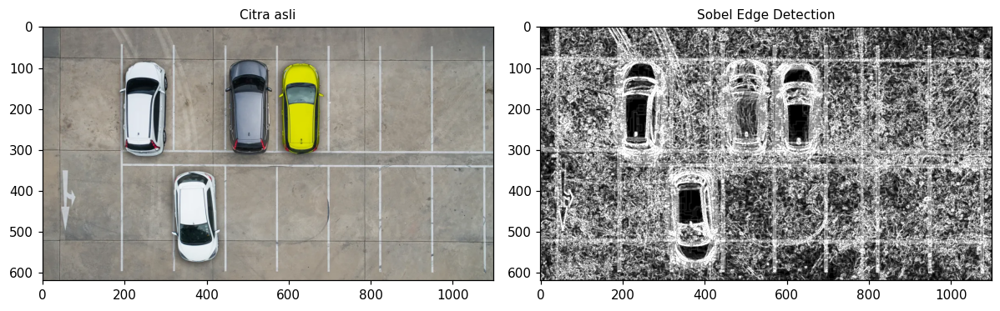

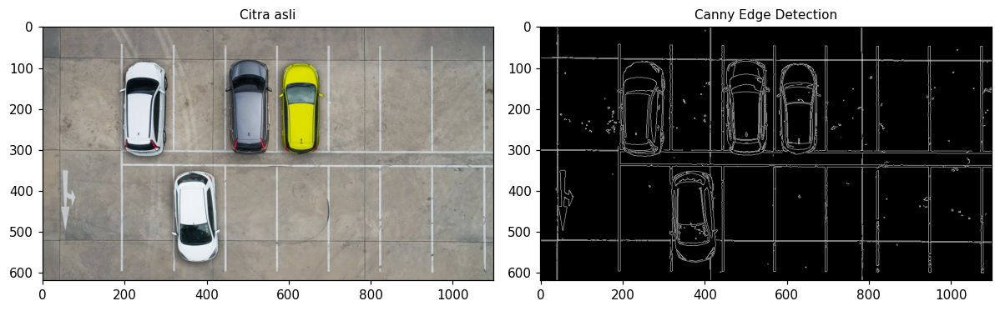

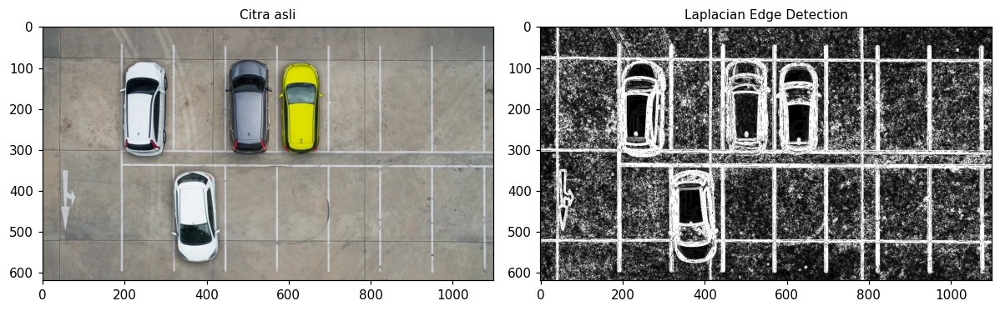

In [ ]:
car = read_image('Object Detection/car-park.jpg')
car_gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)
sobel_x = cv.Sobel(car_gray, cv.CV_64F, 1, 0, ksize=5)
sobel_y = cv.Sobel(car_gray, cv.CV_64F, 0, 1, ksize=5)
sobel_xy = cv.addWeighted(cv.convertScaleAbs(sobel_x), 0.5,
                          cv.convertScaleAbs(sobel_y), 0.5, 0)
canny_edges = cv.Canny(car_gray, 100, 200)
laplacian_edges = cv.Laplacian(cv.GaussianBlur(car_gray, (3, 3), 0),
                               cv.CV_64F, ksize=5)
laplacian_edges = cv.convertScaleAbs(laplacian_edges)

for nama, edges in [('Sobel Edge Detection', sobel_xy),
                    ('Canny Edge Detection', canny_edges),
                    ('Laplacian Edge Detection', laplacian_edges)]:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    show_rgb(ax[0], car, 'Citra asli')
    show_gray(ax[1], edges, nama)
    plt.tight_layout()
    plt.show()


### 5. Harris Corner dan Shi-Tomasi Detection

Kedua metode memakai `chess-board.jpg`. Harris menandai respons sudut yang melewati ambang relatif. Shi-Tomasi memakai `goodFeaturesToTrack` pada citra grayscale, lalu menggambar titik sudut dengan warna biru seperti contoh modul.

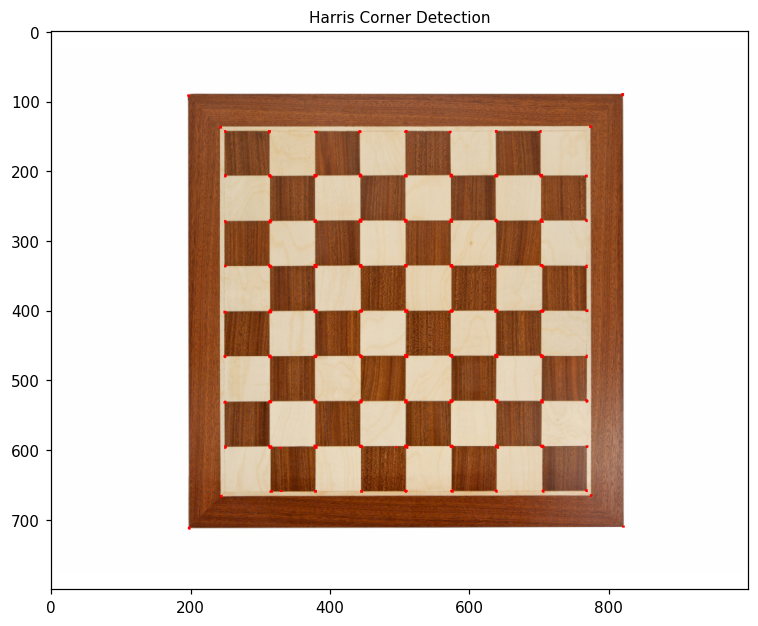

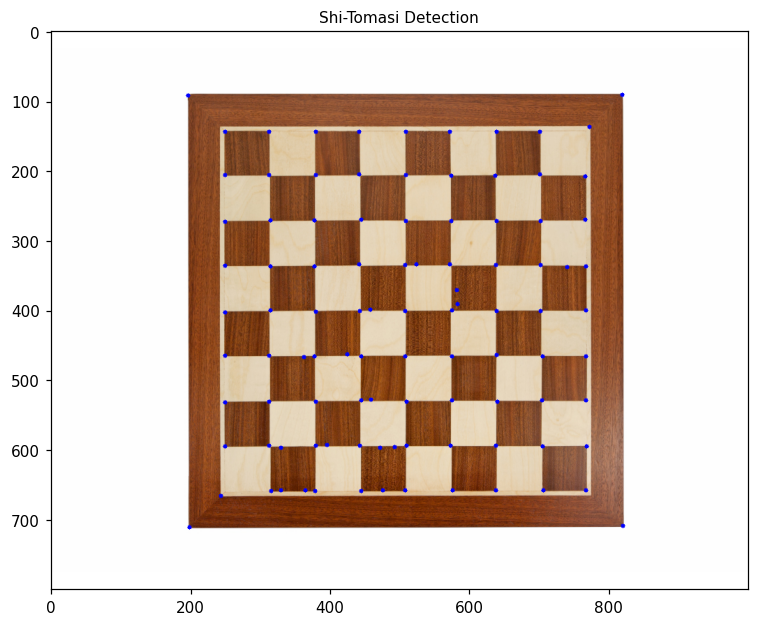

Sudut Harris tertandai: 2238 piksel
Jumlah titik Shi-Tomasi: 100


In [ ]:
chess = read_image('Object Detection/chess-board.jpg')
chess_gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

# Ambang memakai nilai relatif terhadap respons maksimum. Nilai 0.01 dipilih
# agar sudut kotak papan ikut tertandai, bukan hanya beberapa titik terkuat.
harris_response = cv.cornerHarris(np.float32(chess_gray), 2, 3, 0.04)
harris_mask = (harris_response > 0.01 * harris_response.max()).astype(np.uint8)
harris_mask = cv.dilate(harris_mask, None)
harris_result = chess.copy()
harris_result[harris_mask.astype(bool)] = [0, 0, 255]

shi_result = chess.copy()
shi_corners = cv.goodFeaturesToTrack(chess_gray, maxCorners=100,
                                     qualityLevel=0.01, minDistance=10)
if shi_corners is not None:
    for corner in np.int32(shi_corners).reshape(-1, 2):
        cv.circle(shi_result, tuple(corner), 3, (255, 0, 0), -1)

fig, ax = plt.subplots(figsize=(7, 7))
show_rgb(ax, harris_result, 'Harris Corner Detection')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 7))
show_rgb(ax, shi_result, 'Shi-Tomasi Detection')
plt.tight_layout()
plt.show()
print('Sudut Harris tertandai:', int(harris_mask.sum()), 'piksel')
print('Jumlah titik Shi-Tomasi:', 0 if shi_corners is None else len(shi_corners))


### 6. Hough Transform untuk grid sudoku

Urutan pemrosesan mengikuti teori modul: Canny, dilasi untuk menyatukan tepi grid, erosi untuk mengurangi ketebalan, lalu `HoughLines`. Garis yang mendekati dua arah dominan grid dipilih dan garis yang berdekatan digabungkan agar gambar tidak dipenuhi duplikasi.

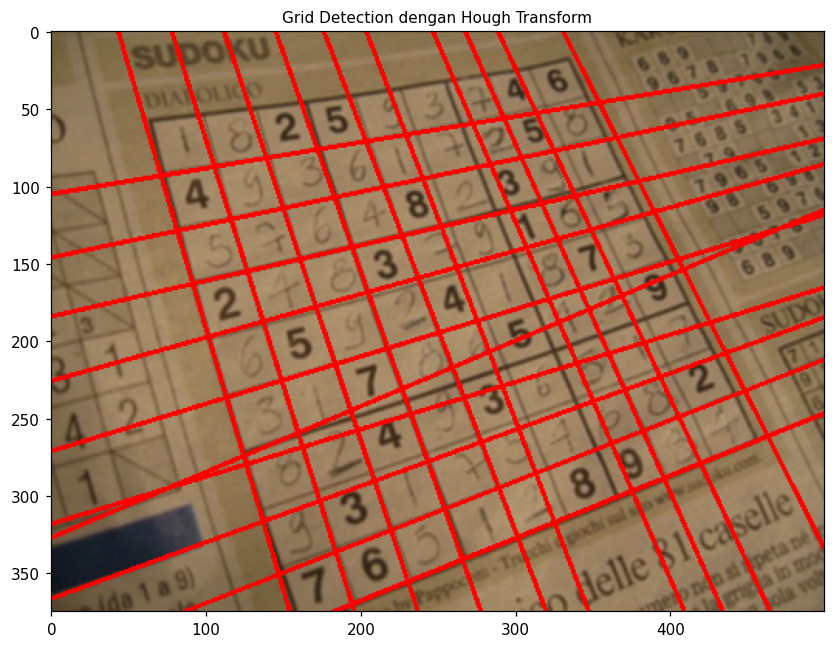

Garis Hough awal: 199
Garis grid setelah penggabungan: 20


In [ ]:
sudoku = read_image('Object Detection/sudoku.jpg')
sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)
sudoku_edges = cv.Canny(sudoku_gray, 50, 150, apertureSize=3)
kernel_grid = np.ones((3, 3), np.uint8)
sudoku_dilated = cv.dilate(sudoku_edges, kernel_grid, iterations=1)
sudoku_grid_edges = cv.erode(sudoku_dilated, kernel_grid, iterations=1)
raw_lines = cv.HoughLines(sudoku_grid_edges, 1, np.pi / 180, 200)

def merge_similar_lines(lines, rho_tol=20, theta_tol=np.deg2rad(4)):
    groups = []
    if lines is None:
        return groups
    for rho, theta in lines[:, 0]:
        for group in groups:
            if abs(group['rho'] - rho) <= rho_tol and abs(group['theta'] - theta) <= theta_tol:
                n = group['count']
                group['rho'] = (group['rho'] * n + rho) / (n + 1)
                group['theta'] = (group['theta'] * n + theta) / (n + 1)
                group['count'] += 1
                break
        else:
            groups.append({'rho': float(rho), 'theta': float(theta), 'count': 1})
    return groups

merged_lines = merge_similar_lines(raw_lines)
grid_lines = [line for line in merged_lines
              if 66 <= np.rad2deg(line['theta']) <= 82
              or 148 <= np.rad2deg(line['theta']) <= 165]
sudoku_result = sudoku.copy()
for line in grid_lines:
    rho, theta = line['rho'], line['theta']
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    pt1 = (int(x0 + 1000 * -b), int(y0 + 1000 * a))
    pt2 = (int(x0 - 1000 * -b), int(y0 - 1000 * a))
    cv.line(sudoku_result, pt1, pt2, (0, 0, 255), 2)

fig, ax = plt.subplots(figsize=(8, 6))
show_rgb(ax, sudoku_result, 'Grid Detection dengan Hough Transform')
plt.tight_layout()
plt.show()
print('Garis Hough awal:', 0 if raw_lines is None else len(raw_lines))
print('Garis grid setelah penggabungan:', len(grid_lines))


### 7. Contour detection pada gambar laptop

Gambar `laptop.jpg` berukuran besar. Gambar diperkecil untuk mempercepat deteksi, diubah ke grayscale, dihaluskan, lalu diproses Canny dan `findContours`. Kontur besar dengan bentuk cembung empat sisi dipakai sebagai batas tiap laptop.

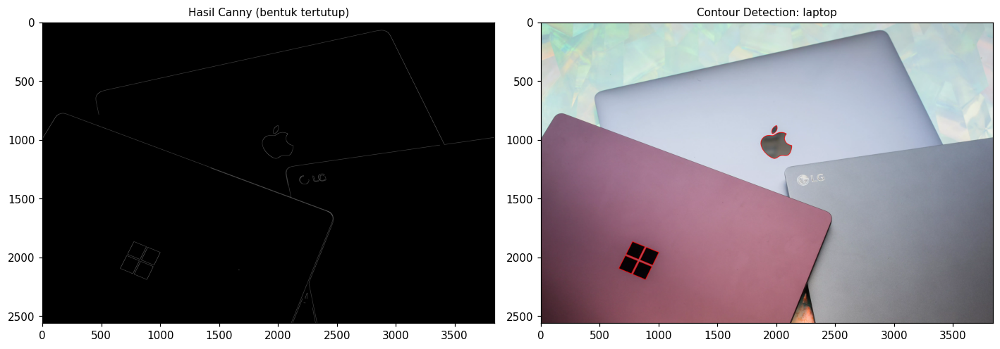

Jumlah kontur: 27
Kontur lambang yang digambar: 11
  area 14235, bbox (780, 2036, 161, 155)
  area 14375, bbox (780, 2036, 161, 155)
  area 14024, bbox (662, 1988, 160, 153)
  area 14170, bbox (662, 1988, 160, 153)
  area 13892, bbox (841, 1917, 159, 151)
  area 14036, bbox (840, 1917, 160, 151)


In [ ]:
laptops = read_image('Object Detection/laptop.jpg')
laptop_gray = cv.cvtColor(laptops, cv.COLOR_BGR2GRAY)
laptop_blur = cv.GaussianBlur(laptop_gray, (7, 7), 0)
laptop_edges = cv.Canny(laptop_blur, 50, 150)
contours, hierarchy = cv.findContours(laptop_edges, cv.RETR_LIST,
                                      cv.CHAIN_APPROX_SIMPLE)
laptop_result = laptops.copy()
selected = []
h, w = laptop_gray.shape
for contour in contours:
    area = cv.contourArea(contour)
    if area < 0.0002 * w * h:
        continue
    perimeter = cv.arcLength(contour, True)
    if perimeter == 0:
        continue
    polygon = cv.approxPolyDP(contour, 0.02 * perimeter, True)
    x, y, bw, bh = cv.boundingRect(contour)
    if 4 <= len(polygon) <= 12 and bw > 40 and bh > 40:
        selected.append(contour)
cv.drawContours(laptop_result, selected, -1, (0, 0, 255), 3)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
show_gray(ax[0], laptop_edges, 'Hasil Canny (bentuk tertutup)')
show_rgb(ax[1], laptop_result, 'Contour Detection: laptop')
plt.tight_layout()
plt.show()
print('Jumlah kontur:', len(contours))
print('Kontur lambang yang digambar:', len(selected))
for contour in selected[:6]:
    x, y, bw, bh = cv.boundingRect(contour)
    print(f'  area {cv.contourArea(contour):.0f}, bbox ({x}, {y}, {bw}, {bh})')


## D2. Praktikum Feature Matching dan Face Detection

### 8. Face detection pada gambar lain

Cascade `haarcascade_frontalface_alt.xml` dipakai sesuai modul. Setiap gambar diubah menjadi grayscale. Gambar kucing dan cereal juga ditampilkan; keduanya membantu melihat batas metode Haar wajah manusia pada objek yang bukan wajah manusia.

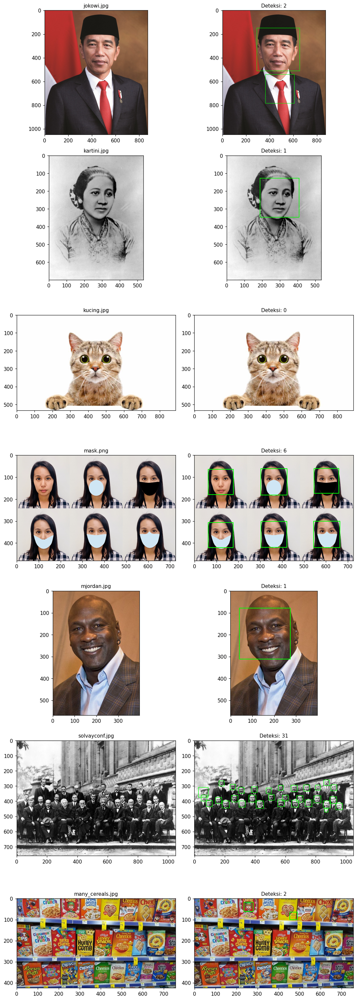

In [ ]:
face_cascade = cv.CascadeClassifier(path('haarcascades/haarcascade_frontalface_alt.xml'))
if face_cascade.empty():
    raise FileNotFoundError('Model haarcascade_frontalface_alt.xml tidak berhasil dibaca.')

face_files = ['jokowi.jpg', 'kartini.jpg', 'kucing.jpg', 'mask.png',
              'mjordan.jpg', 'solvayconf.jpg', 'many_cereals.jpg']
fig, axes = plt.subplots(len(face_files), 2, figsize=(10, 4 * len(face_files)))
for row, filename in enumerate(face_files):
    color = read_image('facedet/' + filename)
    gray = cv.cvtColor(color, cv.COLOR_BGR2GRAY)
    boxes = face_cascade.detectMultiScale(gray, scaleFactor=1.05,
                                          minNeighbors=3, minSize=(20, 20))
    detected = color.copy()
    for x, y, w, h in boxes:
        cv.rectangle(detected, (x, y), (x + w, y + h), (0, 255, 0), 2)
    show_rgb(axes[row, 0], color, filename)
    show_rgb(axes[row, 1], detected, f'Deteksi: {len(boxes)}')
plt.tight_layout()
plt.show()


Pada gambar wajah manusia, kotak mengikuti area wajah yang dideteksi cascade. Hasil pada masker dan foto berisi banyak orang dapat berbeda karena ukuran dan posisi wajah. Cascade frontal face bukan model khusus kucing; kotak dari cascade tersebut pada gambar kucing bukan deteksi wajah kucing yang andal.

### 9. Deteksi wajah kucing

OpenCV menyediakan pretrained feature untuk wajah kucing. Cascade `haarcascade_frontalcatface_extended.xml` digunakan pada `kucing.jpg`. Deteksi kadang mengembalikan kotak gabungan untuk seluruh kepala dan kotak lebih kecil pada wajah, sehingga hasil ditampilkan apa adanya.

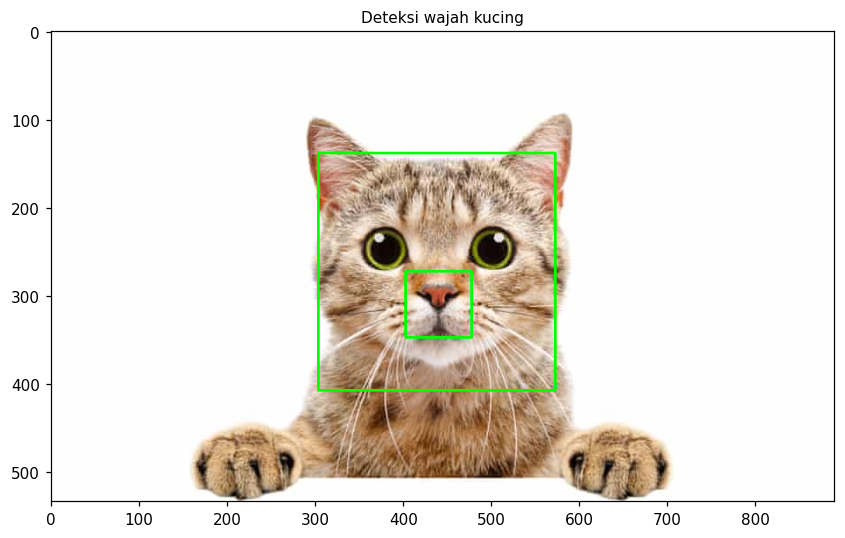

Kotak wajah kucing: 2


In [ ]:
cat_cascade = cv.CascadeClassifier(path('haarcascades/haarcascade_frontalcatface_extended.xml'))
cat_image = read_image('facedet/kucing.jpg')
cat_gray = cv.cvtColor(cat_image, cv.COLOR_BGR2GRAY)
cat_boxes = cat_cascade.detectMultiScale(cat_gray, scaleFactor=1.05,
                                         minNeighbors=3, minSize=(30, 30))
cat_result = cat_image.copy()
for x, y, w, h in cat_boxes:
    cv.rectangle(cat_result, (x, y), (x + w, y + h), (0, 255, 0), 2)
fig, ax = plt.subplots(figsize=(10, 5))
show_rgb(ax, cat_result, 'Deteksi wajah kucing')
plt.tight_layout()
plt.show()
print('Kotak wajah kucing:', len(cat_boxes))


### 10. Eyes detection pada wajah Pak Prabowo

Cascade mata diterapkan pada area wajah yang diperoleh dari cascade wajah. Pembatasan ROI mengurangi deteksi mata palsu di luar wajah.

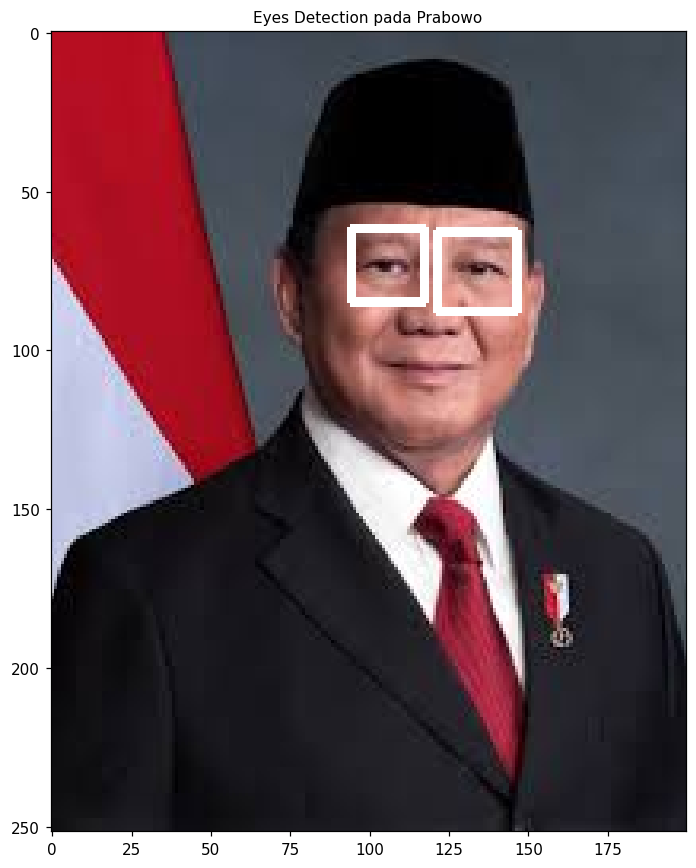

Jumlah kotak mata: 2


In [ ]:
prabowo = read_image('prabowo.jpg')
prabowo_gray = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)
face_boxes = face_cascade.detectMultiScale(prabowo_gray, scaleFactor=1.1,
                                          minNeighbors=4)
eye_cascade = cv.CascadeClassifier(path('haarcascades/haarcascade_eye.xml'))
eyes_result = prabowo.copy()
eye_boxes = []
for x, y, w, h in face_boxes:
    roi = prabowo_gray[y:y + int(h * 0.60), x:x + w]
    eyes = eye_cascade.detectMultiScale(roi, scaleFactor=1.05,
                                        minNeighbors=3, minSize=(15, 15))
    for ex, ey, ew, eh in eyes:
        eye_boxes.append((x + ex, y + ey, ew, eh))
        cv.rectangle(eyes_result, (x + ex, y + ey),
                     (x + ex + ew, y + ey + eh), (255, 255, 255), 2)
fig, ax = plt.subplots(figsize=(7, 8))
show_rgb(ax, eyes_result, 'Eyes Detection pada Prabowo')
plt.tight_layout()
plt.show()
print('Jumlah kotak mata:', len(eye_boxes))


### 11. Deteksi senyuman

Cascade `haarcascade_smile.xml` dijalankan pada bagian bawah setiap wajah, karena mulut berada di area tersebut. Parameter cascade smile lebih ketat: `scaleFactor=1.7` dan `minNeighbors=20` dipakai agar tekstur lain tidak ikut ditandai. Berkas gambar people pada modul tidak tersedia di folder aset, sehingga praktikum memakai foto wajah yang ada. Pada `mask.png` senyum tidak terdeteksi karena mulut tertutup masker, dan hasil itu ditampilkan apa adanya.


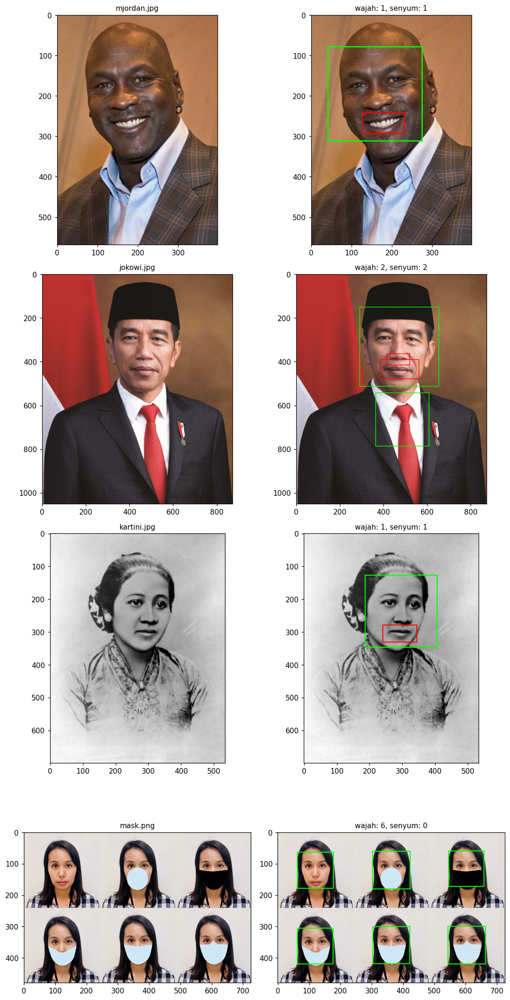

Total senyum terdeteksi: 4


In [ ]:
# Berkas gambar people pada modul tidak disertakan di folder aset, sehingga
# praktikum memakai foto wajah yang tersedia dan tetap menjalankan cascade senyum.
smile_cascade = cv.CascadeClassifier(path('haarcascades/haarcascade_smile.xml'))
if smile_cascade.empty():
    raise FileNotFoundError('Model haarcascade_smile.xml tidak berhasil dibaca.')

smile_files = ['mjordan.jpg', 'jokowi.jpg', 'kartini.jpg', 'mask.png']
fig, axes = plt.subplots(len(smile_files), 2, figsize=(10, 5 * len(smile_files)))
total_smiles = 0
for row, filename in enumerate(smile_files):
    image = read_image('facedet/' + filename)
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.05, 3, minSize=(30, 30))
    result = image.copy()
    smile_count = 0
    for x, y, w, h in faces:
        cv.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
        # Area mulut berada pada bagian bawah wajah.
        mouth_y = y + int(h * 0.55)
        mouth_roi = gray[mouth_y:y + h, x:x + w]
        smiles = smile_cascade.detectMultiScale(mouth_roi, scaleFactor=1.7,
                                                minNeighbors=20, minSize=(15, 15))
        for sx, sy, sw, sh in smiles:
            smile_count += 1
            cv.rectangle(result, (x + sx, mouth_y + sy),
                         (x + sx + sw, mouth_y + sy + sh), (0, 0, 255), 2)
    total_smiles += smile_count
    show_rgb(axes[row, 0], image, filename)
    show_rgb(axes[row, 1], result, f'wajah: {len(faces)}, senyum: {smile_count}')
plt.tight_layout()
plt.show()
print('Total senyum terdeteksi:', total_smiles)


### 12. Face tracking dengan kamera di Google Colab

Browser Colab tidak meneruskan kamera komputer melalui `cv.VideoCapture`. Sel berikut meminta satu frame kamera melalui JavaScript, kemudian mendeteksi wajah pada frame tersebut. Jalankan sel saat notebook berada di Google Colab dan izinkan akses kamera.

Mode lokal: kamera Colab tidak tersedia. Jalankan sel ini di Google Colab dan izinkan akses kamera untuk memperoleh frame asli.


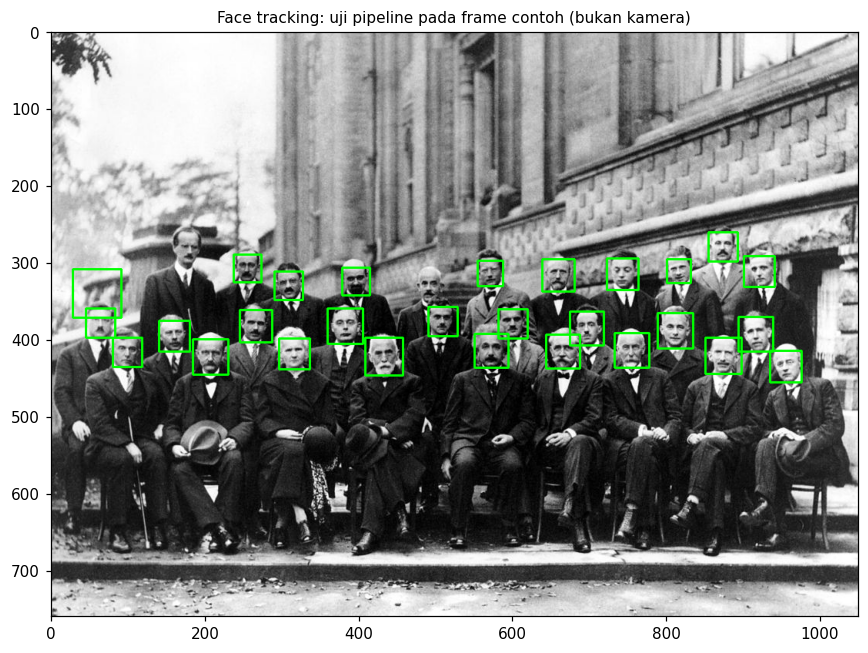

In [ ]:
# Sel ini mengikuti modul: akses kamera di Google Colab memakai JavaScript.
# Di luar Colab, eval_js tidak tersedia, sehingga sel harus dijalankan di Colab.
try:
    from google.colab.output import eval_js
    from IPython.display import Javascript, display
    from base64 import b64decode
    from PIL import Image
    from io import BytesIO
    DALAM_COLAB = True
except ImportError:
    DALAM_COLAB = False
    print('Mode lokal: kamera Colab tidak tersedia. Jalankan sel ini di Google Colab '
          'dan izinkan akses kamera untuk memperoleh frame asli.')

def capture_frame():
    display(Javascript(r"""
    async function captureFrame() {
      const div = document.createElement('div');
      const video = document.createElement('video');
      const button = document.createElement('button');
      button.textContent = 'Ambil frame kamera';
      div.appendChild(video);
      div.appendChild(button);
      document.body.appendChild(div);
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      await new Promise(resolve => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.9);
    }
    """))
    data = eval_js('captureFrame()')
    return np.array(Image.open(BytesIO(b64decode(data.split(',')[1]))))

if DALAM_COLAB:
    frame_rgb = capture_frame()
    judul_frame = 'Face tracking: frame kamera'
else:
    # Tanpa kamera, pipeline deteksi yang sama diuji pada frame contoh.
    frame_rgb = cv.cvtColor(read_image('facedet/solvayconf.jpg'), cv.COLOR_BGR2RGB)
    judul_frame = 'Face tracking: uji pipeline pada frame contoh (bukan kamera)'

frame_bgr = cv.cvtColor(frame_rgb, cv.COLOR_RGB2BGR)
frame_gray = cv.cvtColor(frame_bgr, cv.COLOR_BGR2GRAY)
tracked = frame_bgr.copy()
for x, y, w, h in face_cascade.detectMultiScale(frame_gray, 1.1, 4):
    cv.rectangle(tracked, (x, y), (x + w, y + h), (0, 255, 0), 2)
plt.figure(figsize=(8, 6))
show_rgb(plt.gca(), tracked, judul_frame)
plt.tight_layout()
plt.show()


### 13. Blurring wajah yang terdeteksi

Wajah pada foto Pak Michael Jordan diburamkan dengan `medianBlur`. Area di luar kotak deteksi tidak diubah.

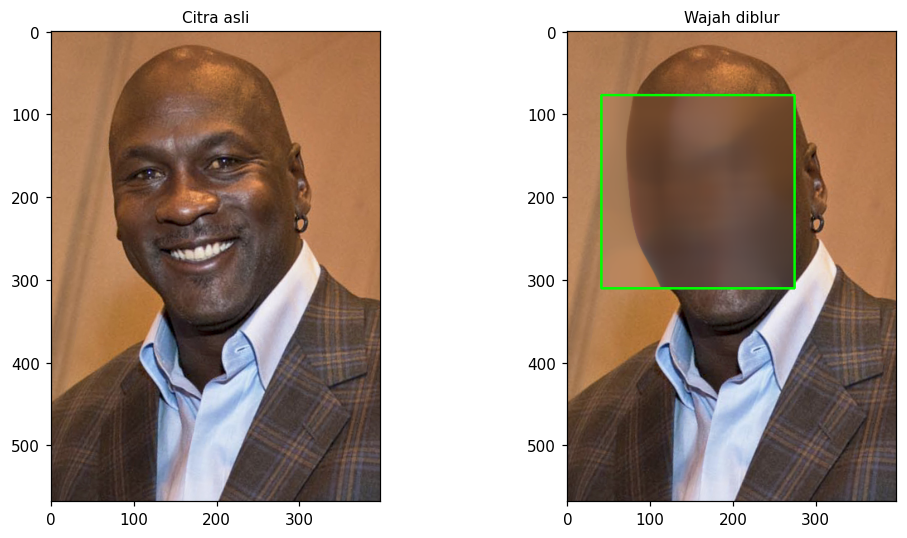

In [ ]:
blur_input = read_image('facedet/mjordan.jpg')
blur_gray = cv.cvtColor(blur_input, cv.COLOR_BGR2GRAY)
blur_boxes = face_cascade.detectMultiScale(blur_gray, 1.05, 3)
blur_result = blur_input.copy()
for x, y, w, h in blur_boxes:
    roi = blur_result[y:y + h, x:x + w]
    ksize = max(15, (min(w, h) // 3) | 1)
    blur_result[y:y + h, x:x + w] = cv.medianBlur(roi, ksize)
    cv.rectangle(blur_result, (x, y), (x + w, y + h), (0, 255, 0), 2)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
show_rgb(ax[0], blur_input, 'Citra asli')
show_rgb(ax[1], blur_result, 'Wajah diblur')
plt.tight_layout()
plt.show()


### 14. Mengolah gambar KTM

#### a-b. Membaca citra dan menampilkan foto KTM

Foto KTM diambil dari berkas yang tersedia pada repo praktikum. Koordinat crop foto diatur setelah memeriksa orientasi citra, lalu area foto ditampilkan seperti keluaran pada modul.

Dimensi foto KTM: (1055, 1600, 3)


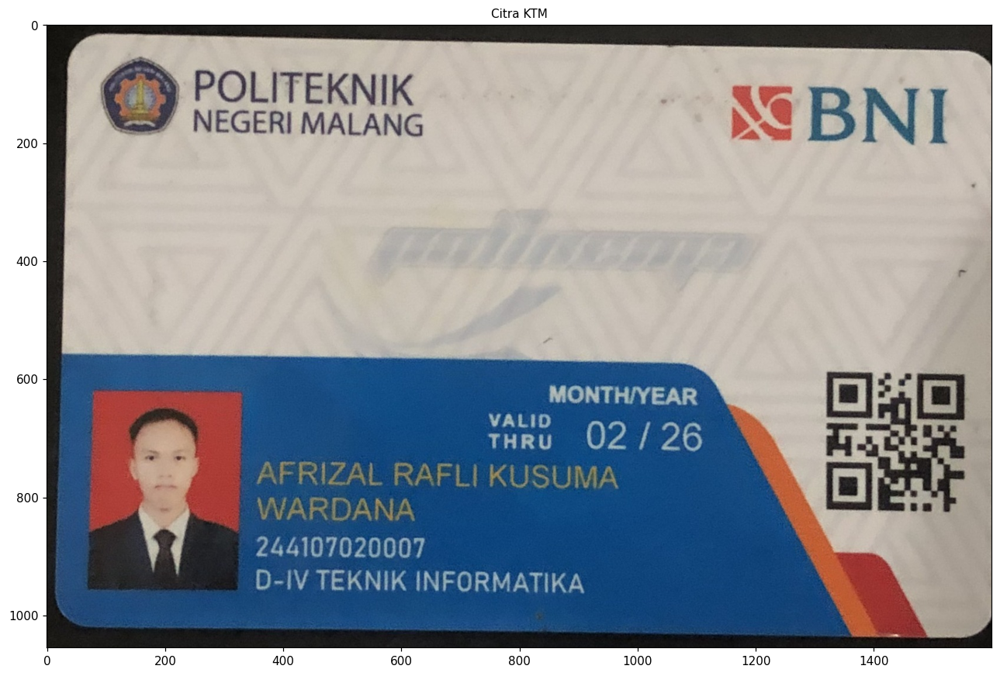

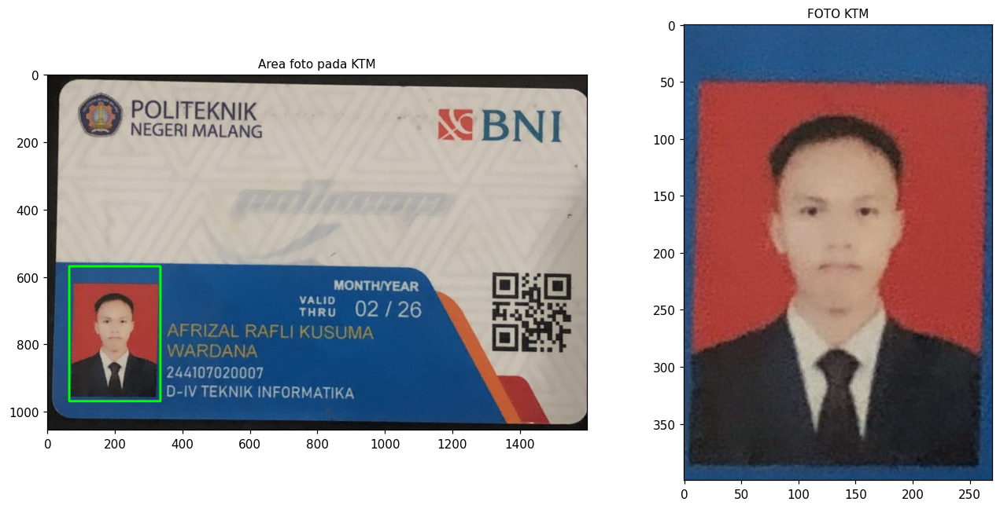

Ukuran foto KTM: (400, 270, 3)


In [ ]:
ktm = cv.imread('../WEEK 1/Kelompok/KTM_RIZAL.jpeg')
if ktm is None:
    raise FileNotFoundError('Foto KTM tidak ditemukan pada WEEK 1/Kelompok/KTM_RIZAL.jpeg')
ktm_rgb = cv.cvtColor(ktm, cv.COLOR_BGR2RGB)
print('Dimensi foto KTM:', ktm.shape)
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(ktm_rgb)
ax.set_title('Citra KTM')
ax.axis('on')
plt.tight_layout()
plt.show()

# Area foto pada KTM_RIZAL.jpeg, orientasi gambar mengikuti berkas sumber.
KTM_ROI = (65, 570, 335, 970)  # x0, y0, x1, y1
foto_ktm = ktm_rgb[KTM_ROI[1]:KTM_ROI[3], KTM_ROI[0]:KTM_ROI[2]]
ktm_bertanda = ktm_rgb.copy()
cv.rectangle(ktm_bertanda, (KTM_ROI[0], KTM_ROI[1]), (KTM_ROI[2], KTM_ROI[3]),
             (0, 255, 0), 6)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(ktm_bertanda)
ax[0].set_title('Area foto pada KTM')
ax[0].axis('on')
ax[1].imshow(foto_ktm)
ax[1].set_title('FOTO KTM')
ax[1].axis('on')
plt.tight_layout()
plt.show()
print('Ukuran foto KTM:', foto_ktm.shape)


#### c. Deteksi obyek KTM dengan Feature Matching

KTM dipakai sebagai citra template. Adegan yang berisi barang lain diambil dari foto KTM pada citra `KTM1D.jpg`; pencocokan dilakukan dengan ORB dan brute-force Hamming. Karena foto sumber menampilkan KTM dengan orientasi berbeda, code mencoba rotasi seperempat putaran dan memilih homografi dengan jumlah inlier terbesar. Bila empat titik sudut homografi berhasil dihitung, poligon KTM digambar pada adegan.

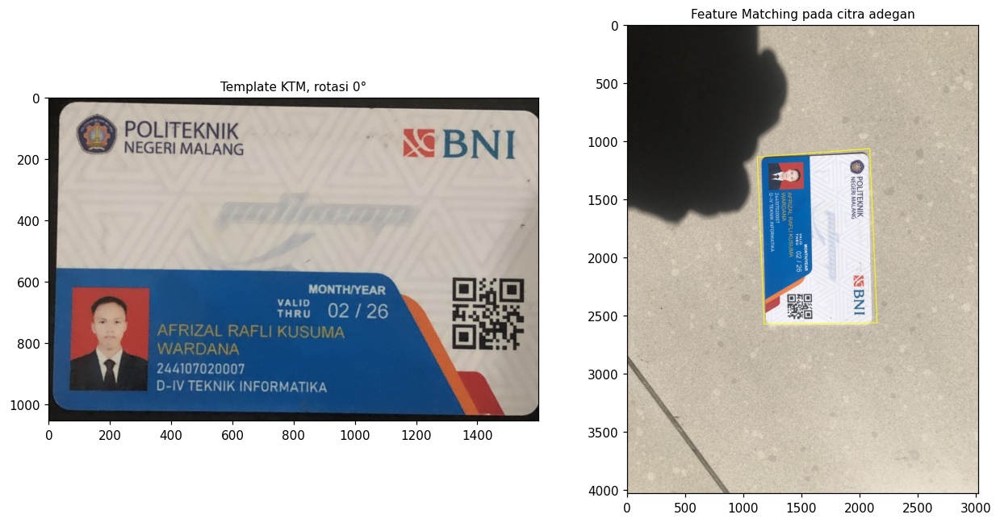

Good matches: 642 | inlier homography: 589


In [ ]:
scene_path = '../WEEK 1/KTM1D.jpg'
scene = cv.imread(scene_path)
if scene is None:
    raise FileNotFoundError(f'Citra adegan tidak ditemukan: {scene_path}')
scene_gray = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)

orb = cv.ORB_create(nfeatures=2500)
scene_keypoints, scene_descriptors = orb.detectAndCompute(scene_gray, None)
best_match = None
for rotation in (0, 90, 180, 270):
    rotated = np.rot90(cv.cvtColor(ktm, cv.COLOR_BGR2RGB), k=rotation // 90)
    template_gray = cv.cvtColor(rotated, cv.COLOR_RGB2GRAY)
    keypoints, descriptors = orb.detectAndCompute(template_gray, None)
    if descriptors is None or scene_descriptors is None:
        continue
    pairs = cv.BFMatcher(cv.NORM_HAMMING).knnMatch(descriptors, scene_descriptors, k=2)
    good = [m for m, n in pairs if m.distance < 0.75 * n.distance]
    candidate = (len(good), rotation, rotated, keypoints, descriptors, good)
    if best_match is None or candidate[0] > best_match[0]:
        best_match = candidate

if best_match is None:
    raise RuntimeError('ORB tidak menemukan descriptor pada salah satu citra.')
count, rotation, template_rgb, keypoints, descriptors, good = best_match
feature_result = scene.copy()
inlier_count = 0
if len(good) >= 8:
    src_pts = np.float32([keypoints[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([scene_keypoints[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    if H is not None:
        h, w = template_rgb.shape[:2]
        corners = np.float32([[0, 0], [w - 1, 0],
                              [w - 1, h - 1], [0, h - 1]]).reshape(-1, 1, 2)
        projected = cv.perspectiveTransform(corners, H).astype(np.int32)
        cv.polylines(feature_result, [projected], True, (0, 255, 255), 5)
        inlier_count = int(inliers.sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(template_rgb)
ax[0].set_title(f'Template KTM, rotasi {rotation}°')
ax[0].axis('on')
show_rgb(ax[1], feature_result, 'Feature Matching pada citra adegan')
plt.tight_layout()
plt.show()
print('Good matches:', count, '| inlier homography:', inlier_count)


## Kesimpulan

Template matching, deteksi tepi, corner detection, Hough Transform, dan contour detection memberi keluaran yang berbeda sesuai ciri yang dicari. Cascade Haar dapat menandai wajah, mata, dan senyum pada gambar, sementara feature matching ORB menghubungkan fitur lokal KTM dengan foto sumber. Hasil sangat bergantung pada kontras, orientasi, ukuran obyek, serta ambang yang dipilih.